In [1]:
import os, sys, json, glob, random, shutil, platform, warnings, time, zipfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
import sklearn
import tensorflow as tf
from tensorflow import keras
from keras import layers
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, matthews_corrcoef, balanced_accuracy_score)
warnings.filterwarnings("ignore")

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"     # developer dry-run switch; leave as is

SEED          = 42
IMG_SIZE      = (224, 224)
BATCH_SIZE    = 16                     # PPT baseline batch size
FEAT_BATCH    = 64                     # batch size for feature extraction / top-block training
CLASS_NAMES   = ["no_heart_risk", "heart_risk"]      # index 0 = No HR, 1 = HR (positive)
DISPLAY_NAMES = {"no_heart_risk": "No HR", "heart_risk": "HR"}

# ---------------- PPT baseline (reference only) ----------------
RUN_PPT_BASELINE = False               # True = retrain the 5-epoch PPT baseline (about 65 min on your CPU)
BASE_EPOCHS, BASE_LR, BASE_DROPOUT, BASE_RESCALE = 5, 1e-3, 0.2, 1.0 / 255.0
PPT_COUNTS  = {"train": 508, "val": 177, "test": 172}
PPT_WEIGHTS = {"No HR": 0.5632, "HR": 4.4561}

# ---------------- Improved MobileNetV2 ----------------
# Where to cut the network. Everything BEFORE the cut is frozen & cached; everything AFTER is fine-tuned.
#   "block_13_project_BN": 7x7x160  | ~1.5 M trainable params | fastest      (start here)
#   "block_12_add"       : 14x14x96 | ~1.7 M trainable params | slower, more adaptable
#   "block_9_add"        : 14x14x64 | ~2.0 M trainable params | slowest, most adaptable (try if accuracy < 90 %)
CUT_LAYER       = "block_13_project_BN"
FLIP_AUG        = False                # True = also cache horizontally-flipped train images (2x extraction time, 2x data)
USE_CLASS_WEIGHT = False               # classes are ~60/40 here, so plain training maximises accuracy
HEAD_EPOCHS, HEAD_LR = 3, 1e-3         # phase 1: train new head only
FT_EPOCHS,  FT_LR    = 30, 1e-4        # phase 2: fine-tune top blocks (early stopping will cut this short)
HEAD_UNITS, DROPOUT  = 256, 0.3
TTA = True                             # average prediction with horizontally flipped image
CHECK_DUPLICATES = True                # detect byte-identical images shared between train and val/test
TARGET_ACC = 0.90

if SMOKE_TEST:
    HEAD_EPOCHS, FT_EPOCHS = 1, 2

# ---------------- Paths (yours) ----------------
ART        = Path(r"C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts")
if SMOKE_TEST:
    ART = Path("artifacts_smoke")
DIRS = {k: ART / k for k in ["Models", "Plots", "Encoders", "Scalers", "Reports", "Logs"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
FEAT_DIR = ART / "Cache"               # cached features (can be deleted when you are done)
FEAT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

env = {"python": sys.version.split()[0], "platform": platform.platform(), "tensorflow": tf.__version__,
       "keras": keras.__version__, "numpy": np.__version__, "pandas": pd.__version__,
       "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
       "gpus": [g.name for g in tf.config.list_physical_devices("GPU")]}
json.dump(env, open(DIRS["Logs"] / "environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))

{
  "python": "3.12.0",
  "platform": "Windows-11-10.0.26200-SP0",
  "tensorflow": "2.18.0",
  "keras": "3.6.0",
  "numpy": "2.0.2",
  "pandas": "2.2.3",
  "scikit_learn": "1.5.2",
  "matplotlib": "3.9.2",
  "gpus": []
}


In [2]:
DATA_ROOT = r"C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Dataset"

if SMOKE_TEST:
    DATA_ROOT = os.environ.get("SMOKE_DATA", "smoke_data")
DATA_ROOT = Path(DATA_ROOT)
for s in ["train", "val", "test"]:
    for c in CLASS_NAMES:
        assert (DATA_ROOT / s / c).is_dir(), f"Missing folder: {DATA_ROOT / s / c}"
print("Using dataset at:", DATA_ROOT.resolve())

Using dataset at: C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Dataset


class     HR  No HR  Total
split                     
train  23808  15872  39680
val     3000   2000   5000
test    2934   1956   4890 
Total images: 49570

Class weights  No HR = 1.2500 | HR = 0.8333


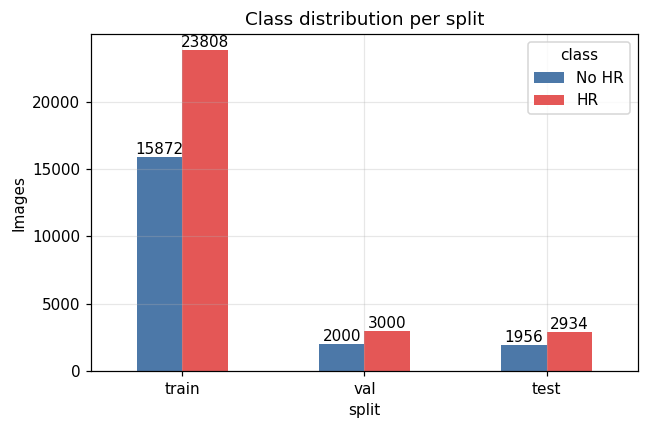

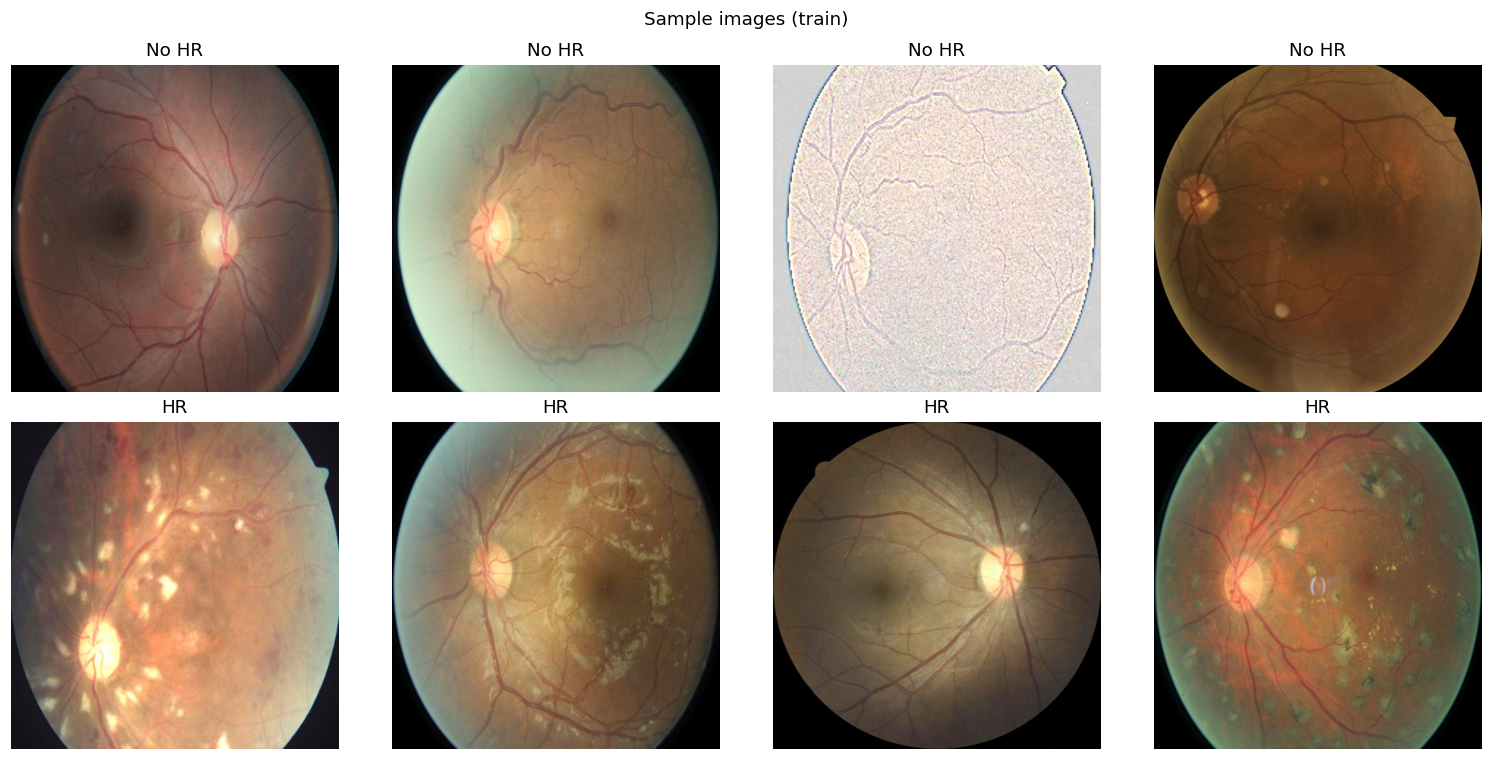

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
rows = []
for split in ["train", "val", "test"]:
    for c in CLASS_NAMES:
        n = sum(1 for p in (DATA_ROOT / split / c).rglob("*") if p.suffix.lower() in IMG_EXT)
        rows.append({"split": split, "class": DISPLAY_NAMES[c], "count": n})
dist = pd.DataFrame(rows).pivot(index="split", columns="class", values="count").loc[["train", "val", "test"]]
dist["Total"] = dist.sum(axis=1)
print(dist, "\nTotal images:", int(dist["Total"].sum()))
dist.to_csv(DIRS["Reports"] / "dataset_distribution.csv")

n_tr = dist.loc["train", ["No HR", "HR"]].astype(float)
CLASS_WEIGHT = {0: n_tr.sum() / (2 * n_tr["No HR"]), 1: n_tr.sum() / (2 * n_tr["HR"])}
print("\nClass weights  No HR = %.4f | HR = %.4f" % (CLASS_WEIGHT[0], CLASS_WEIGHT[1]))

ax = dist[["No HR", "HR"]].plot(kind="bar", figsize=(6, 4), color=["#4C78A8", "#E45756"])
ax.set_title("Class distribution per split"); ax.set_ylabel("Images"); plt.xticks(rotation=0)
for cnt in ax.containers: ax.bar_label(cnt)
plt.tight_layout(); plt.savefig(DIRS["Plots"] / "01_class_distribution.png"); plt.show()

from PIL import Image
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r, c in enumerate(CLASS_NAMES):
    files = sorted(p for p in (DATA_ROOT / "train" / c).rglob("*") if p.suffix.lower() in IMG_EXT)
    pick = random.Random(SEED).sample(files, min(4, len(files)))
    for k in range(4):
        axes[r, k].axis("off")
        if k < len(pick):
            axes[r, k].imshow(Image.open(pick[k]).convert("RGB")); axes[r, k].set_title(DISPLAY_NAMES[c])
plt.suptitle("Sample images (train)"); plt.tight_layout()
plt.savefig(DIRS["Plots"] / "02_sample_images.png"); plt.show()

In [4]:
# ---- Duplicate / leakage check: byte-identical files shared between train and val/test ----
def md5_of(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

hash_cache = {}
def hashes(split):
    out = {}
    for c in CLASS_NAMES:
        for p in sorted((DATA_ROOT / split / c).rglob("*")):
            if p.suffix.lower() in IMG_EXT:
                out[str(p)] = md5_of(p)
    return out

DUP_INFO = {}
if CHECK_DUPLICATES:
    t0 = time.time()
    h_tr, h_va, h_te = hashes("train"), hashes("val"), hashes("test")
    s_tr = set(h_tr.values())
    DUP_INFO = {"test_path_hash": h_te, "val_path_hash": h_va, "train_hash_set": s_tr}
    n_te = sum(h in s_tr for h in h_te.values()); n_va = sum(h in s_tr for h in h_va.values())
    print(f"Hashing took {time.time()-t0:.0f}s")
    print(f"Identical to a TRAIN image -> test: {n_te}/{len(h_te)} | val: {n_va}/{len(h_va)} | "
          f"duplicates inside train: {len(h_tr) - len(s_tr)}")
    if n_te or n_va:
        print("WARNING: train/test overlap exists. Accuracy on the full test set is inflated; the notebook will also "
              "report accuracy on the test images that do NOT appear in train.")

Hashing took 79s
Identical to a TRAIN image -> test: 19/4890 | val: 17/5000 | duplicates inside train: 232


In [5]:
encoder = OrdinalEncoder(categories=[CLASS_NAMES]).fit(np.array(CLASS_NAMES).reshape(-1, 1))
joblib.dump(encoder, DIRS["Encoders"] / "label_encoder.joblib")
json.dump({"class_to_index": {c: i for i, c in enumerate(CLASS_NAMES)},
           "index_to_display": {i: DISPLAY_NAMES[c] for i, c in enumerate(CLASS_NAMES)},
           "positive_class": "heart_risk"}, open(DIRS["Encoders"] / "label_map.json", "w"), indent=2)

joblib.dump(MinMaxScaler((0, 1)).fit(np.array([[0.0], [255.0]])),  DIRS["Scalers"] / "pixel_minmax_scaler.joblib")
joblib.dump(MinMaxScaler((-1, 1)).fit(np.array([[0.0], [255.0]])), DIRS["Scalers"] / "pixel_scaler_minus1_1.joblib")
json.dump({"img_size": list(IMG_SIZE), "channels": 3, "baseline_rescale": "x/255 (0..1)",
           "improved_rescale": "x/127.5 - 1 (-1..1), applied inside the model", "cut_layer": CUT_LAYER,
           "batch_size": BATCH_SIZE, "feature_batch": FEAT_BATCH},
          open(DIRS["Scalers"] / "preprocessing_config.json", "w"), indent=2)

AUTOTUNE = tf.data.AUTOTUNE
def make_ds(split, shuffle, batch):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / split, labels="inferred", label_mode="binary", class_names=CLASS_NAMES,
        color_mode="rgb", image_size=IMG_SIZE, batch_size=batch, shuffle=shuffle, seed=SEED)

val_raw  = make_ds("val",  False, FEAT_BATCH)
test_raw = make_ds("test", False, FEAT_BATCH)
val_ds, test_ds = val_raw.prefetch(AUTOTUNE), test_raw.prefetch(AUTOTUNE)
y_val  = np.concatenate([y.numpy() for _, y in val_raw]).ravel().astype(int)
y_test = np.concatenate([y.numpy() for _, y in test_raw]).ravel().astype(int)
print("val labels:", np.bincount(y_val), "| test labels:", np.bincount(y_test), "(0 = No HR, 1 = HR)")

# mask of test images that do not appear (byte-identical) in train
if DUP_INFO:
    test_unique_mask = np.array([DUP_INFO["test_path_hash"][str(Path(p))] not in DUP_INFO["train_hash_set"]
                                 for p in test_raw.file_paths])
else:
    test_unique_mask = np.ones(len(y_test), dtype=bool)
print("Test images not present in train:", int(test_unique_mask.sum()), "/", len(y_test))

Found 5000 files belonging to 2 classes.
Found 4890 files belonging to 2 classes.
val labels: [2000 3000] | test labels: [1956 2934] (0 = No HR, 1 = HR)
Test images not present in train: 4871 / 4890


In [6]:
def predict_proba(model, ds, tta=False):
    p = model.predict(ds, verbose=0).ravel()
    if tta:
        flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        p = (p + model.predict(flipped, verbose=0).ravel()) / 2.0
    return p

def best_threshold(y_true, p, metric="accuracy"):
    # chosen on the VALIDATION set only, never on test
    grid = np.linspace(0.05, 0.95, 91)
    fn = (lambda t: accuracy_score(y_true, (p >= t).astype(int))) if metric == "accuracy" else \
         (lambda t: f1_score(y_true, (p >= t).astype(int), zero_division=0))
    return float(grid[int(np.argmax([fn(t) for t in grid]))])

def evaluate(y_true, p, thr=0.5, name="model"):
    pred = (p >= thr).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1]); tn, fp, fn, tp = cm.ravel(); eps = 1e-7
    loss = float(-np.mean(y_true * np.log(np.clip(p, eps, 1 - eps)) + (1 - y_true) * np.log(np.clip(1 - p, eps, 1 - eps))))
    out = {"model": name, "threshold": thr, "accuracy": accuracy_score(y_true, pred), "loss": loss,
           "balanced_accuracy": balanced_accuracy_score(y_true, pred), "mcc": matthews_corrcoef(y_true, pred),
           "roc_auc": roc_auc_score(y_true, p), "pr_auc": average_precision_score(y_true, p),
           "sensitivity_HR_recall": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
           "HR_precision": precision_score(y_true, pred, zero_division=0), "HR_f1": f1_score(y_true, pred, zero_division=0),
           "NoHR_precision": precision_score(y_true, pred, pos_label=0, zero_division=0),
           "NoHR_recall": recall_score(y_true, pred, pos_label=0, zero_division=0),
           "NoHR_f1": f1_score(y_true, pred, pos_label=0, zero_division=0),
           "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
    return out, cm

def plot_cm(cm, title, fname):
    fig, ax = plt.subplots(figsize=(4.6, 4.2)); ax.imshow(cm, cmap="Blues"); ax.grid(False)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No HR", "HR"], yticklabels=["No HR", "HR"],
           xlabel="Predicted", ylabel="Actual", title=title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=15, color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(DIRS["Plots"] / fname); plt.show()

def full_report(name, y_true, p, thr, tag):
    m, cm = evaluate(y_true, p, thr, name)
    print(f"\n===== {name} (threshold={thr:.2f}) =====")
    print("Confusion matrix [[TN, FP],[FN, TP]]:\n", cm)
    print(classification_report(y_true, (p >= thr).astype(int), target_names=["No HR", "HR"], digits=4, zero_division=0))
    print({k: round(v, 4) for k, v in m.items() if isinstance(v, float)})
    plot_cm(cm, f"{name}\nthr={thr:.2f}", f"cm_{tag}.png")
    pd.DataFrame({"y_true": y_true, "prob_HR": p, "pred": (p >= thr).astype(int)}).to_csv(DIRS["Reports"] / f"predictions_{tag}.csv", index=False)
    return m

def plot_history(histories, title, fname, mark_phase=None):
    h = {k: sum([hh[k] for hh in histories], []) for k in histories[0]}
    ep = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(ep, h["accuracy"], "o-", label="Training Accuracy"); ax[0].plot(ep, h["val_accuracy"], "o-", label="Validation Accuracy")
    ax[0].set(title=f"{title}: Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[0].legend()
    ax[1].plot(ep, h["loss"], "o-", label="Training Loss"); ax[1].plot(ep, h["val_loss"], "o-", label="Validation Loss")
    ax[1].set(title=f"{title}: Loss", xlabel="Epoch", ylabel="Loss"); ax[1].legend()
    if mark_phase:
        for a in ax: a.axvline(mark_phase + 0.5, color="gray", ls="--", alpha=.6)
    plt.tight_layout(); plt.savefig(DIRS["Plots"] / fname); plt.show()

In [7]:
BASE_PATH = DIRS["Models"] / "mobilenetv2_baseline.keras"
res_mb = res_mb_t = None; p_val_mb = p_test_mb = None

def build_ppt_baseline():
    backbone = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False,
                                              weights=None if SMOKE_TEST else "imagenet")
    backbone.trainable = False
    return keras.Sequential([keras.Input(shape=IMG_SIZE + (3,)), layers.Rescaling(BASE_RESCALE), backbone,
                             layers.GlobalAveragePooling2D(), layers.Dropout(BASE_DROPOUT),
                             layers.Dense(1, activation="sigmoid")], name="sequential")

mobilenet = None
if BASE_PATH.exists() and not RUN_PPT_BASELINE:
    mobilenet = keras.models.load_model(BASE_PATH); print("Loaded saved PPT baseline:", BASE_PATH)
elif RUN_PPT_BASELINE:
    train_b = make_ds("train", True, BATCH_SIZE).prefetch(AUTOTUNE)
    mobilenet = build_ppt_baseline()
    mobilenet.compile(optimizer=keras.optimizers.Adam(BASE_LR), loss="binary_crossentropy", metrics=["accuracy"])
    print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in mobilenet.trainable_weights), "(PPT: 1,281)")
    hist_mb = mobilenet.fit(train_b, validation_data=make_ds("val", False, BATCH_SIZE), epochs=BASE_EPOCHS,
                            class_weight=CLASS_WEIGHT, verbose=2)
    mobilenet.save(BASE_PATH)
    pd.DataFrame(hist_mb.history).to_csv(DIRS["Logs"] / "history_mobilenetv2.csv", index_label="epoch")
    plot_history([hist_mb.history], "MobileNetV2 (PPT baseline)", "03_mobilenetv2_training_curves.png")
else:
    print("No saved baseline found and RUN_PPT_BASELINE=False -> skipping the baseline comparison.")

if mobilenet is not None:
    p_val_mb, p_test_mb = predict_proba(mobilenet, val_ds), predict_proba(mobilenet, test_ds)
    res_mb   = full_report("A) MobileNetV2 PPT baseline", y_test, p_test_mb, 0.5, "04_mobilenetv2_ppt_thr0.5")
    thr_mb   = best_threshold(y_val, p_val_mb)
    res_mb_t = full_report("A') PPT baseline + val-tuned threshold", y_test, p_test_mb, thr_mb, "05_mobilenetv2_ppt_tuned")

No saved baseline found and RUN_PPT_BASELINE=False -> skipping the baseline comparison.


In [8]:
use_weights = None if SMOKE_TEST else "imagenet"
base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights=use_weights)
cut_tensor = base.get_layer(CUT_LAYER).output
FEAT_SHAPE = tuple(cut_tensor.shape[1:])
print("Cut layer:", CUT_LAYER, "-> feature shape", FEAT_SHAPE)

# frozen part (runs once) and trainable part (shares the SAME layer objects/weights as `base`)
extractor_core = keras.Model(base.input, cut_tensor, name="frozen_part")
top_base       = keras.Model(cut_tensor, base.output, name="top_blocks")

scale = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenet_rescale")
img_in = keras.Input(shape=IMG_SIZE + (3,))
extractor = keras.Model(img_in, extractor_core(scale(img_in)), name="extractor")

head = keras.Sequential([layers.GlobalAveragePooling2D(), layers.Dropout(DROPOUT),
                         layers.Dense(HEAD_UNITS, activation="relu"), layers.Dropout(DROPOUT),
                         layers.Dense(1, activation="sigmoid")], name="head")

feat_in   = keras.Input(shape=FEAT_SHAPE)
top_model = keras.Model(feat_in, head(top_base(feat_in)), name="top_model")          # trains on cached features
full_in   = keras.Input(shape=IMG_SIZE + (3,))
full_model = keras.Model(full_in, head(base(scale(full_in))), name="mobilenetv2_finetuned")   # deployable model
print("Top-block parameters (fine-tuned in phase 2):", sum(int(np.prod(w.shape)) for w in top_base.weights))

Cut layer: block_13_project_BN -> feature shape (7, 7, 160)
Top-block parameters (fine-tuned in phase 2): 1541440


In [9]:
def extract_features(split, flip=False):
    tag = f"{split}{'_flip' if flip else ''}_{CUT_LAYER}_{IMG_SIZE[0]}"
    fx, fy = FEAT_DIR / f"{tag}_X.npy", FEAT_DIR / f"{tag}_y.npy"
    if fx.exists() and fy.exists():
        print("loaded cache:", fx.name); return np.load(fx).astype("float32"), np.load(fy)
    ds = make_ds(split, False, FEAT_BATCH)                       # unshuffled -> labels stay aligned
    y = np.concatenate([b.numpy() for _, b in ds]).ravel().astype("float32")
    if flip: ds = ds.map(lambda x, t: (tf.image.flip_left_right(x), t))
    t0 = time.time()
    X = extractor.predict(ds.prefetch(AUTOTUNE), verbose=1)
    print(f"{tag}: {X.shape} in {(time.time()-t0)/60:.1f} min")
    np.save(fx, X.astype("float16")); np.save(fy, y)
    return X.astype("float32"), y

X_tr, y_tr = extract_features("train")
if FLIP_AUG:
    Xf, yf = extract_features("train", flip=True); X_tr, y_tr = np.concatenate([X_tr, Xf]), np.concatenate([y_tr, yf]); del Xf
X_va, y_va = extract_features("val"); X_te, y_te = extract_features("test")
assert (y_va.astype(int) == y_val).all() and (y_te.astype(int) == y_test).all(), "label order mismatch"
print("Cached features:", X_tr.shape, X_va.shape, X_te.shape)

Found 39680 files belonging to 2 classes.
620/620 ━━━━━━━━━━━━━━━━━━━━ 560s 900ms/step
train_block_13_project_BN_224: (39680, 7, 7, 160) in 9.4 min
Found 5000 files belonging to 2 classes.
79/79 ━━━━━━━━━━━━━━━━━━━━ 67s 844ms/step
val_block_13_project_BN_224: (5000, 7, 7, 160) in 1.1 min
Found 4890 files belonging to 2 classes.
77/77 ━━━━━━━━━━━━━━━━━━━━ 62s 806ms/step
test_block_13_project_BN_224: (4890, 7, 7, 160) in 1.0 min
Cached features: (39680, 7, 7, 160) (5000, 7, 7, 160) (4890, 7, 7, 160)


Epoch 1/3
620/620 - 75s - 121ms/step - accuracy: 0.7424 - auc: 0.8136 - loss: 0.5158 - val_accuracy: 0.7604 - val_auc: 0.8489 - val_loss: 0.4732
Epoch 2/3
620/620 - 77s - 123ms/step - accuracy: 0.7649 - auc: 0.8408 - loss: 0.4804 - val_accuracy: 0.7746 - val_auc: 0.8592 - val_loss: 0.4579
Epoch 3/3
620/620 - 71s - 114ms/step - accuracy: 0.7705 - auc: 0.8488 - loss: 0.4694 - val_accuracy: 0.7850 - val_auc: 0.8668 - val_loss: 0.4516
Trainable parameters in phase 2: 1838913
Epoch 1/30
620/620 - 200s - 323ms/step - accuracy: 0.7736 - auc: 0.8505 - loss: 0.4730 - val_accuracy: 0.8066 - val_auc: 0.8889 - val_loss: 0.4173 - learning_rate: 1.0000e-04
Epoch 2/30
620/620 - 230s - 372ms/step - accuracy: 0.8092 - auc: 0.8869 - loss: 0.4110 - val_accuracy: 0.8138 - val_auc: 0.8970 - val_loss: 0.4009 - learning_rate: 1.0000e-04
Epoch 3/30
620/620 - 201s - 324ms/step - accuracy: 0.8278 - auc: 0.9058 - loss: 0.3753 - val_accuracy: 0.8144 - val_auc: 0.8964 - val_loss: 0.3969 - learning_rate: 1.0000e-04

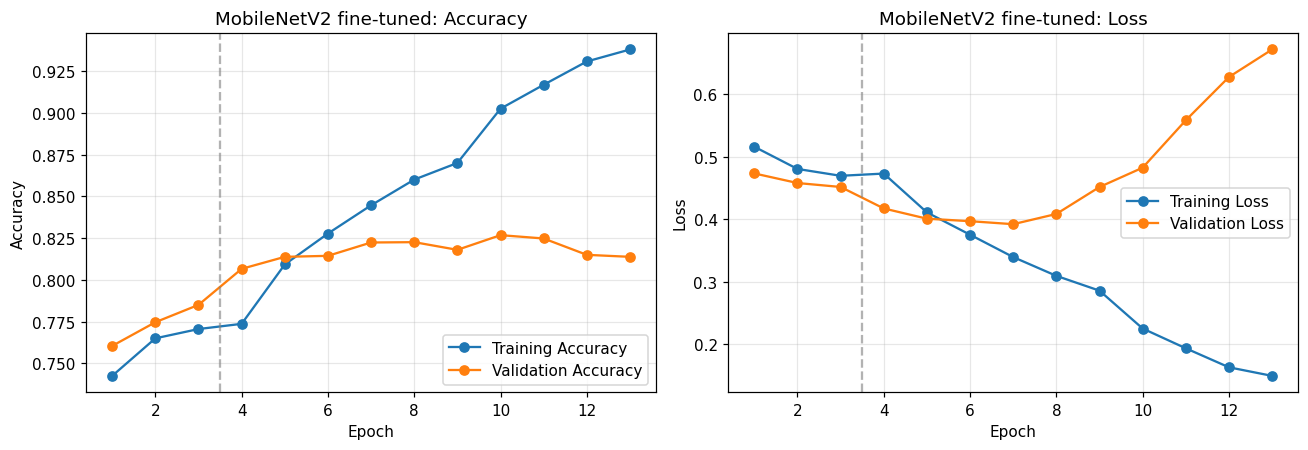

Best validation accuracy during training: 0.8268


In [10]:
METRICS = [keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")]
cw = CLASS_WEIGHT if USE_CLASS_WEIGHT else None

# ---------- Phase 1: head only ----------
top_base.trainable = False
top_model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss="binary_crossentropy", metrics=METRICS)
t0 = time.time()
h1 = top_model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=HEAD_EPOCHS, batch_size=FEAT_BATCH,
                   shuffle=True, class_weight=cw, verbose=2)

# ---------- Phase 2: fine-tune top blocks (BatchNorm frozen) ----------
top_base.trainable = True
for l in top_base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
top_model.compile(optimizer=keras.optimizers.Adam(FT_LR), loss="binary_crossentropy", metrics=METRICS)
print("Trainable parameters in phase 2:", sum(int(np.prod(w.shape)) for w in top_model.trainable_weights))
cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
       keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1)]
h2 = top_model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=FT_EPOCHS, batch_size=FEAT_BATCH,
                   shuffle=True, class_weight=cw, callbacks=cbs, verbose=2)
print(f"Training finished in {(time.time()-t0)/60:.1f} min")

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
pd.DataFrame(hist).to_csv(DIRS["Logs"] / "history_mobilenetv2_finetuned.csv", index_label="epoch")
plot_history([h1.history, h2.history], "MobileNetV2 fine-tuned", "06_mobilenetv2_finetuned_curves.png", mark_phase=len(h1.history["loss"]))
print("Best validation accuracy during training: %.4f" % max(h2.history["val_accuracy"]))

In [11]:
# ---------- Sanity check: the deployable full model must equal top_model on the same images ----------
xb, _ = next(iter(val_raw))
f_ref = top_model.predict(extractor.predict(xb, verbose=0), verbose=0).ravel()
f_full = full_model.predict(xb, verbose=0).ravel()
print("max |top_model - full_model| =", float(np.abs(f_ref - f_full).max()))
assert np.abs(f_ref - f_full).max() < 1e-3, "full model does not match the trained top model"

full_model.save(DIRS["Models"] / "mobilenetv2_finetuned.keras")
print("saved", DIRS["Models"] / "mobilenetv2_finetuned.keras")

max |top_model - full_model| = 0.0
saved C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Models\mobilenetv2_finetuned.keras



===== B) MobileNetV2 fine-tuned (thr 0.5) (threshold=0.50) =====
Confusion matrix [[TN, FP],[FN, TP]]:
 [[1500  456]
 [ 504 2430]]
              precision    recall  f1-score   support

       No HR     0.7485    0.7669    0.7576      1956
          HR     0.8420    0.8282    0.8351      2934

    accuracy                         0.8037      4890
   macro avg     0.7952    0.7975    0.7963      4890
weighted avg     0.8046    0.8037    0.8041      4890

{'threshold': 0.5, 'accuracy': 0.8037, 'loss': 0.4272, 'balanced_accuracy': np.float64(0.7975), 'mcc': np.float64(0.5928), 'roc_auc': np.float64(0.8776), 'pr_auc': np.float64(0.9261), 'sensitivity_HR_recall': np.float64(0.8282), 'specificity': np.float64(0.7669), 'HR_precision': np.float64(0.842), 'HR_f1': np.float64(0.8351), 'NoHR_precision': np.float64(0.7485), 'NoHR_recall': np.float64(0.7669), 'NoHR_f1': np.float64(0.7576)}


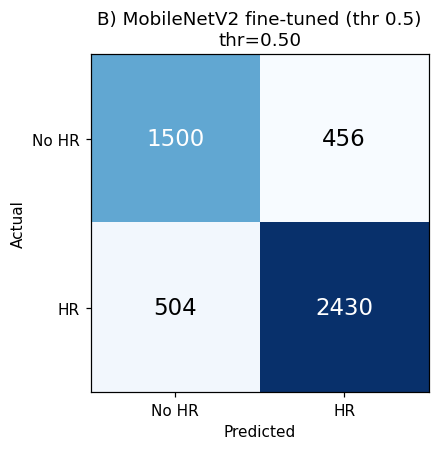


===== B') MobileNetV2 fine-tuned + val-tuned threshold (threshold=0.61) =====
Confusion matrix [[TN, FP],[FN, TP]]:
 [[1666  290]
 [ 694 2240]]
              precision    recall  f1-score   support

       No HR     0.7059    0.8517    0.7720      1956
          HR     0.8854    0.7635    0.8199      2934

    accuracy                         0.7988      4890
   macro avg     0.7957    0.8076    0.7960      4890
weighted avg     0.8136    0.7988    0.8008      4890

{'threshold': 0.61, 'accuracy': 0.7988, 'loss': 0.4272, 'balanced_accuracy': np.float64(0.8076), 'mcc': np.float64(0.6031), 'roc_auc': np.float64(0.8776), 'pr_auc': np.float64(0.9261), 'sensitivity_HR_recall': np.float64(0.7635), 'specificity': np.float64(0.8517), 'HR_precision': np.float64(0.8854), 'HR_f1': np.float64(0.8199), 'NoHR_precision': np.float64(0.7059), 'NoHR_recall': np.float64(0.8517), 'NoHR_f1': np.float64(0.772)}


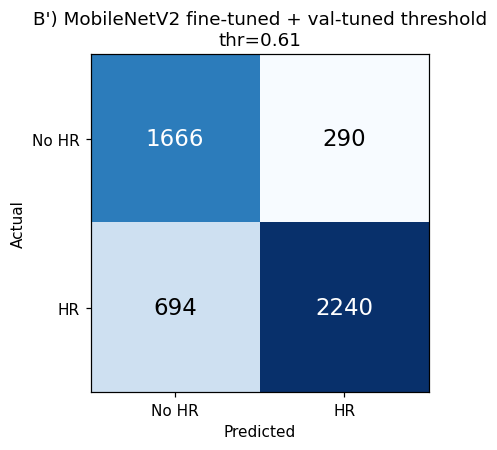


>>> Validation accuracy (tuned thr): 0.8194 | TEST accuracy: 0.7988 | target 0.90 -> not reached
Accuracy on test images NOT in train (4871 images): 0.8007  <- report this one if duplicates exist
Not at target. Next steps in order: (1) CUT_LAYER='block_12_add' then 'block_9_add' (delete nothing; new cache is made), (2) FLIP_AUG=True, (3) FT_LR=3e-4 or 5e-5. Re-run from section 7.


In [12]:
p_val_ft  = predict_proba(full_model, val_ds,  tta=TTA)      # end-to-end on real images (+ flip TTA)
p_test_ft = predict_proba(full_model, test_ds, tta=TTA)
thr_ft    = best_threshold(y_val, p_val_ft, "accuracy")
res_ft_05 = full_report("B) MobileNetV2 fine-tuned (thr 0.5)", y_test, p_test_ft, 0.5, "07_finetuned_thr0.5")
res_ft    = full_report("B') MobileNetV2 fine-tuned + val-tuned threshold", y_test, p_test_ft, thr_ft, "08_finetuned_tuned")

acc_ft = res_ft["accuracy"]
print("\n>>> Validation accuracy (tuned thr): %.4f | TEST accuracy: %.4f | target %.2f -> %s" %
      (accuracy_score(y_val, (p_val_ft >= thr_ft).astype(int)), acc_ft, TARGET_ACC, "REACHED" if acc_ft >= TARGET_ACC else "not reached"))
if not test_unique_mask.all():
    u = test_unique_mask
    print("Accuracy on test images NOT in train (%d images): %.4f  <- report this one if duplicates exist" %
          (u.sum(), accuracy_score(y_test[u], (p_test_ft[u] >= thr_ft).astype(int))))
if acc_ft < TARGET_ACC:
    print("Not at target. Next steps in order: (1) CUT_LAYER='block_12_add' then 'block_9_add' (delete nothing; new cache is made), "
          "(2) FLIP_AUG=True, (3) FT_LR=3e-4 or 5e-5. Re-run from section 7.")

,threshold,accuracy,loss,roc_auc,pr_auc,sensitivity_HR_recall,specificity,HR_precision,HR_f1,NoHR_f1,balanced_accuracy,mcc,TN,FP,FN,TP
model,,,,,,,,,,,,,,,,
B) MobileNetV2 fine-tuned (thr 0.5),0.50,0.8037,0.4272,0.8776,0.9261,0.8282,0.7669,0.8420,0.8351,0.7576,0.7975,0.5928,1500,456,504,2430
B') MobileNetV2 fine-tuned + val-tuned threshold,0.61,0.7988,0.4272,0.8776,0.9261,0.7635,0.8517,0.8854,0.8199,0.7720,0.8076,0.6031,1666,290,694,2240


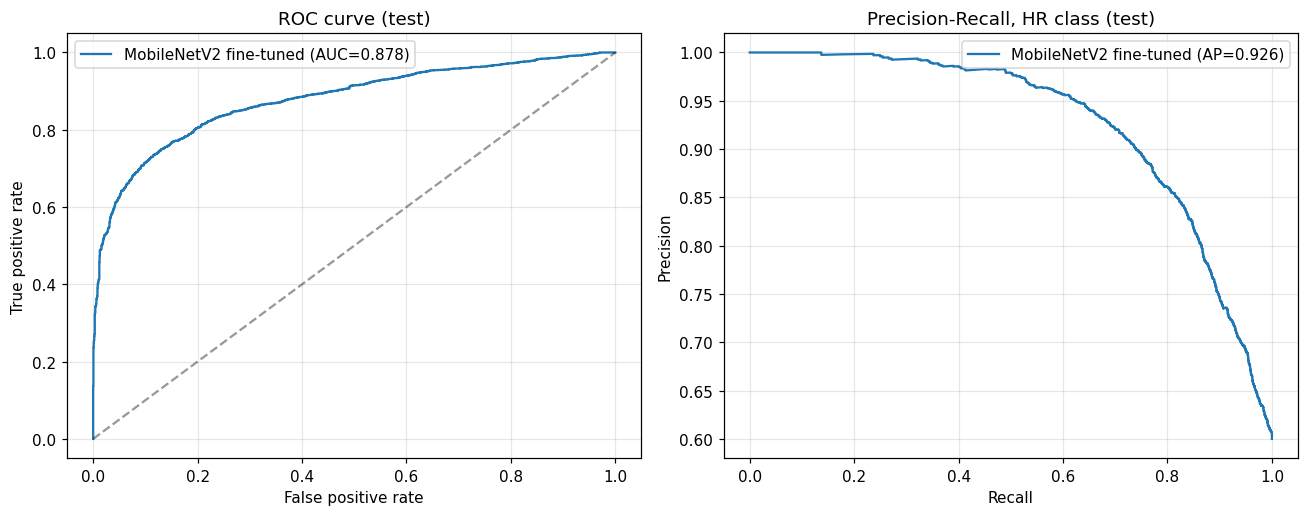

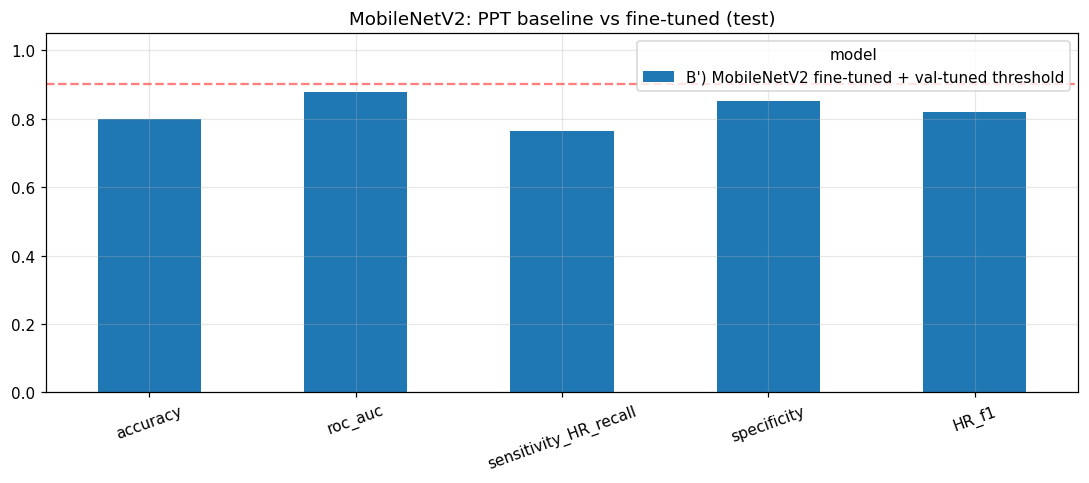

In [13]:
rows_ = [r for r in [res_mb, res_mb_t, res_ft_05, res_ft] if r is not None]
comp = pd.DataFrame(rows_).set_index("model")
show = ["threshold", "accuracy", "loss", "roc_auc", "pr_auc", "sensitivity_HR_recall", "specificity",
        "HR_precision", "HR_f1", "NoHR_f1", "balanced_accuracy", "mcc", "TN", "FP", "FN", "TP"]
display(comp[show].round(4)); comp.to_csv(DIRS["Reports"] / "model_comparison.csv")

curves = [("MobileNetV2 fine-tuned", p_test_ft)] + ([("MobileNetV2 PPT baseline", p_test_mb)] if p_test_mb is not None else [])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for name, p in curves:
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4); ax[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()
ax[1].set(title="Precision-Recall, HR class (test)", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(DIRS["Plots"] / "09_roc_pr_comparison.png"); plt.show()

metrics_bar = ["accuracy", "roc_auc", "sensitivity_HR_recall", "specificity", "HR_f1"]
sel = [n for n in ["A) MobileNetV2 PPT baseline", "B') MobileNetV2 fine-tuned + val-tuned threshold"] if n in comp.index]
comp.loc[sel, metrics_bar].T.plot(kind="bar", figsize=(10, 4.5)); plt.ylim(0, 1.05); plt.axhline(TARGET_ACC, color="r", ls="--", alpha=.5)
plt.title("MobileNetV2: PPT baseline vs fine-tuned (test)"); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(DIRS["Plots"] / "10_model_comparison_bar.png"); plt.show()

In [14]:
full_model.save(DIRS["Models"] / "final_best_model.keras")
final_cfg = {"final_model": "mobilenetv2_finetuned", "decision_threshold": thr_ft, "img_size": list(IMG_SIZE),
             "cut_layer": CUT_LAYER, "tta_flip": TTA, "positive_class": "heart_risk (HR)", "class_order": CLASS_NAMES,
             "seed": SEED, "test_accuracy": float(res_ft["accuracy"]), "test_roc_auc": float(res_ft["roc_auc"]),
             "disclaimer": "Research prototype - not a clinical diagnostic tool."}
json.dump(final_cfg, open(DIRS["Models"] / "final_model_config.json", "w"), indent=2)
json.dump({"ppt_baseline": res_mb, "ppt_baseline_tuned": res_mb_t, "finetuned_thr0.5": res_ft_05, "finetuned_tuned": res_ft},
          open(DIRS["Reports"] / "test_metrics.json", "w"), indent=2, default=float)

def predict_image(path, model_path=DIRS["Models"] / "final_best_model.keras"):
    cfg   = json.load(open(DIRS["Models"] / "final_model_config.json"))
    enc   = joblib.load(DIRS["Encoders"] / "label_encoder.joblib")
    model = keras.models.load_model(model_path)
    arr   = tf.image.resize(np.array(Image.open(path).convert("RGB"), dtype="float32"), tuple(cfg["img_size"])).numpy()[None]
    p = float(model.predict(arr, verbose=0)[0, 0])
    if cfg.get("tta_flip"):
        p = (p + float(model.predict(arr[:, :, ::-1, :], verbose=0)[0, 0])) / 2
    return {"label": enc.categories_[0][int(p >= cfg["decision_threshold"])], "prob_HR": round(p, 4), "threshold": cfg["decision_threshold"]}

sample = next((p for p in sorted((DATA_ROOT / "test" / "heart_risk").rglob("*")) if p.suffix.lower() in IMG_EXT), None)
if sample is not None:
    print(sample.name, "->", predict_image(sample))

import subprocess
with open(ART / "requirements_frozen.txt", "w") as f:
    f.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)

# zip everything except the (large) feature cache
zpath = ART.parent / "artifacts_bundle.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for p in ART.rglob("*"):
        if p.is_file() and FEAT_DIR not in p.parents:
            z.write(p, p.relative_to(ART))
print("Zip:", zpath)
print("Saved:", *sorted(str(p) for p in ART.rglob("*") if p.is_file() and FEAT_DIR not in p.parents), sep="\n  ")

033f2b43de6d-600-HBF.jpg -> {'label': 'heart_risk', 'prob_HR': 0.9999, 'threshold': 0.61}
Zip: C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\artifacts_bundle.zip
Saved:
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Encoders\label_encoder.joblib
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Encoders\label_map.json
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Logs\environment.json
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Logs\history_mobilenetv2_finetuned.csv
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Models\final_best_model.keras
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_2026\Artifacts\Models\final_model_config.json
  C:\Users\HP\PycharmProjects\Retinopathy\.venv\New_HypertensiveRetinopathy_